In [172]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [173]:
df=pd.read_csv(r"C:\Users\ADMIN\OneDrive\ドキュメント\ML\project2\annual_rainfall_prediction_dataset.csv")

In [174]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Record_ID                        10000 non-null  int64  
 1   Year                             10000 non-null  int64  
 2   State                            10000 non-null  object 
 3   Avg_Temperature_C                10000 non-null  float64
 4   Avg_Humidity_percent             10000 non-null  float64
 5   Avg_Pressure_hPa                 10000 non-null  float64
 6   Avg_Wind_Speed_kmh               10000 non-null  float64
 7   Avg_Cloud_Cover_percent          10000 non-null  float64
 8   Previous_Year_Rainfall_mm        10000 non-null  float64
 9   Previous_3_Year_Avg_Rainfall_mm  10000 non-null  float64
 10  Annual_Rainfall_mm               10000 non-null  float64
dtypes: float64(8), int64(2), object(1)
memory usage: 859.5+ KB


In [175]:
df.head()

,Record_ID,Year,State,Avg_Temperature_C,Avg_Humidity_percent,Avg_Pressure_hPa,Avg_Wind_Speed_kmh,Avg_Cloud_Cover_percent,Previous_Year_Rainfall_mm,Previous_3_Year_Avg_Rainfall_mm,Annual_Rainfall_mm
0,1,1988,Uttar Pradesh,17.5,81.5,1012.5,8.8,62.6,783.1,818.9,1178.2
1,2,2013,Punjab,25.7,60.8,1009.1,6.9,68.7,623.9,498.8,626.7
2,3,1999,Assam,25.3,71.0,1020.8,6.4,24.2,2370.0,2042.7,2341.7
3,4,1989,Punjab,31.1,49.6,1012.8,7.4,67.7,825.3,672.5,581.8
4,5,1990,Madhya Pradesh,28.7,72.1,1023.3,5.9,100.0,1585.5,1236.5,1559.8


In [176]:
df.isnull().sum()

Record_ID                          0
Year                               0
State                              0
Avg_Temperature_C                  0
Avg_Humidity_percent               0
Avg_Pressure_hPa                   0
Avg_Wind_Speed_kmh                 0
Avg_Cloud_Cover_percent            0
Previous_Year_Rainfall_mm          0
Previous_3_Year_Avg_Rainfall_mm    0
Annual_Rainfall_mm                 0
dtype: int64

In [177]:
df.duplicated().sum()

np.int64(0)

In [178]:
df.shape

(10000, 11)

In [179]:
df.drop("Record_ID",axis=1,inplace=True)

In [180]:
cat=df.select_dtypes("object")

In [181]:
cat

,State
0,Uttar Pradesh
1,Punjab
2,Assam
3,Punjab
4,Madhya Pradesh
...,...
9995,Tamil Nadu
9996,Rajasthan
9997,Tripura
9998,Arunachal Pradesh


In [182]:
num=df.select_dtypes(exclude="object")

In [183]:
num

,Year,Avg_Temperature_C,Avg_Humidity_percent,Avg_Pressure_hPa,Avg_Wind_Speed_kmh,Avg_Cloud_Cover_percent,Previous_Year_Rainfall_mm,Previous_3_Year_Avg_Rainfall_mm,Annual_Rainfall_mm
0,1988,17.5,81.5,1012.5,8.8,62.6,783.1,818.9,1178.2
1,2013,25.7,60.8,1009.1,6.9,68.7,623.9,498.8,626.7
2,1999,25.3,71.0,1020.8,6.4,24.2,2370.0,2042.7,2341.7
3,1989,31.1,49.6,1012.8,7.4,67.7,825.3,672.5,581.8
4,1990,28.7,72.1,1023.3,5.9,100.0,1585.5,1236.5,1559.8
...,...,...,...,...,...,...,...,...,...
9995,1981,30.3,56.4,996.5,18.2,100.0,1321.5,955.5,1453.4
9996,2011,18.0,56.5,1010.9,25.3,62.5,586.2,494.6,604.9
9997,2021,21.0,75.3,1003.2,3.2,52.7,2642.8,2383.4,2774.7
9998,1984,26.4,59.4,1003.4,11.0,49.4,2861.3,2493.2,2650.3


In [184]:
df.shape

(10000, 10)

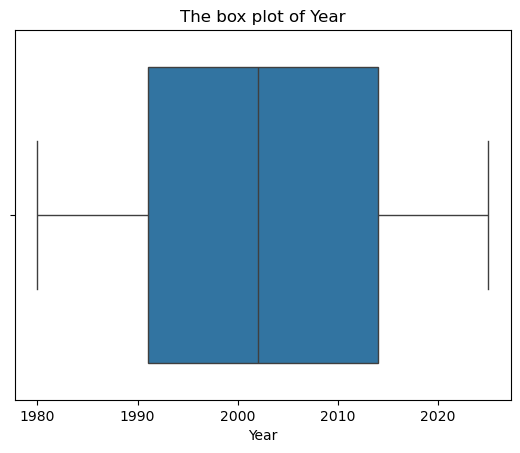

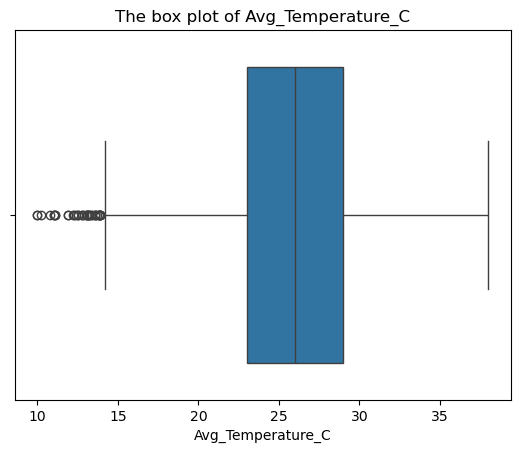

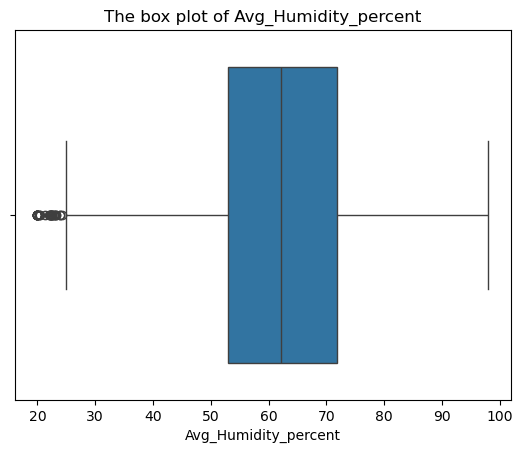

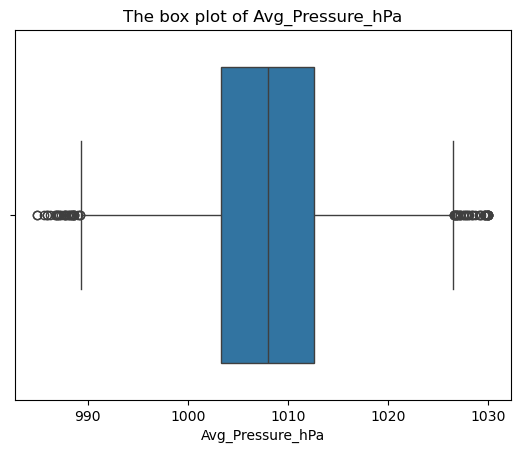

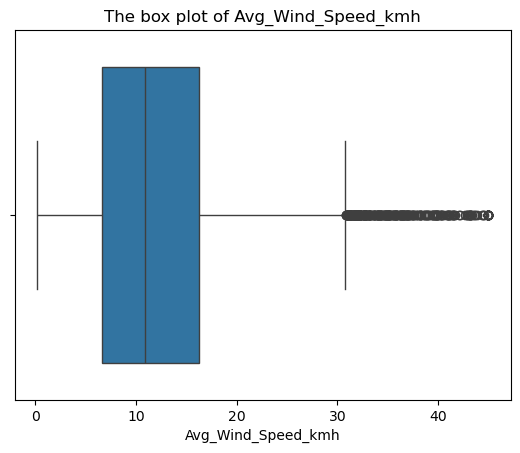

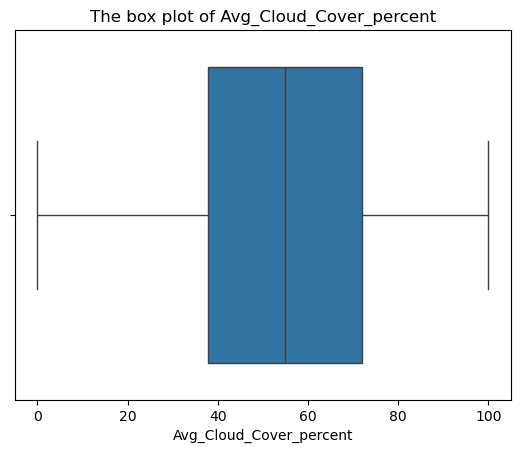

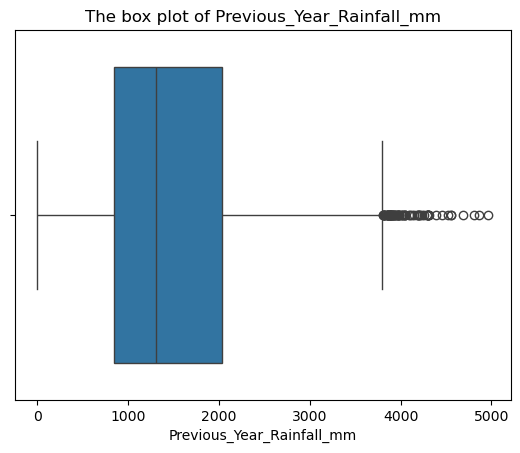

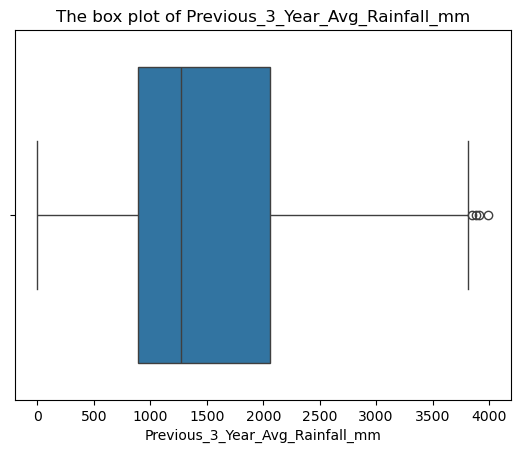

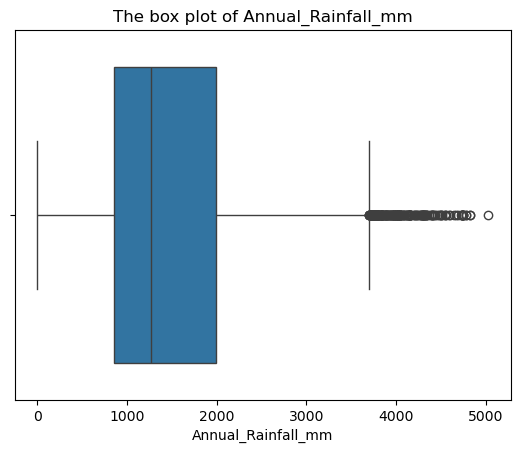

In [185]:
for col in num.columns:
    plt.figure()
    sns.boxplot(x=num[col])
    plt.title(f'The box plot of {col}')

In [186]:
for col in num:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[
        (df[col] >= lower) &
        (df[col] <= upper)
    ]

    print("Dataset shape after removing outliers:", df.shape)

Dataset shape after removing outliers: (10000, 10)
Dataset shape after removing outliers: (9962, 10)
Dataset shape after removing outliers: (9930, 10)
Dataset shape after removing outliers: (9867, 10)
Dataset shape after removing outliers: (9579, 10)
Dataset shape after removing outliers: (9579, 10)
Dataset shape after removing outliers: (9503, 10)
Dataset shape after removing outliers: (9497, 10)
Dataset shape after removing outliers: (9311, 10)


In [187]:
df.shape

(9311, 10)

In [188]:
df.head(2)

,Year,State,Avg_Temperature_C,Avg_Humidity_percent,Avg_Pressure_hPa,Avg_Wind_Speed_kmh,Avg_Cloud_Cover_percent,Previous_Year_Rainfall_mm,Previous_3_Year_Avg_Rainfall_mm,Annual_Rainfall_mm
0,1988,Uttar Pradesh,17.5,81.5,1012.5,8.8,62.6,783.1,818.9,1178.2
1,2013,Punjab,25.7,60.8,1009.1,6.9,68.7,623.9,498.8,626.7


In [189]:
X=df.drop("Annual_Rainfall_mm",axis=1)
y=df['Annual_Rainfall_mm']

In [190]:
X.columns

Index(['Year', 'State', 'Avg_Temperature_C', 'Avg_Humidity_percent',
       'Avg_Pressure_hPa', 'Avg_Wind_Speed_kmh', 'Avg_Cloud_Cover_percent',
       'Previous_Year_Rainfall_mm', 'Previous_3_Year_Avg_Rainfall_mm'],
      dtype='object')

In [191]:
from sklearn.model_selection import train_test_split

In [192]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [193]:
from sklearn.compose import ColumnTransformer

In [194]:
cat_fea=X.select_dtypes(include='object').columns
num_fea=X.select_dtypes(exclude='object').columns

In [195]:
cat_fea

Index(['State'], dtype='object')

In [196]:
num_fea

Index(['Year', 'Avg_Temperature_C', 'Avg_Humidity_percent', 'Avg_Pressure_hPa',
       'Avg_Wind_Speed_kmh', 'Avg_Cloud_Cover_percent',
       'Previous_Year_Rainfall_mm', 'Previous_3_Year_Avg_Rainfall_mm'],
      dtype='object')

In [202]:
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error,root_mean_squared_error

In [203]:
models={
    "RF":RandomForestRegressor(),
    "DT":DecisionTreeRegressor(),
    "ADA":AdaBoostRegressor(),
    "GB":GradientBoostingRegressor(),
    "XG":XGBRegressor()
}

In [204]:
for i in range (len(list(models))):
    model=list(models.values())[i]

    # model training 
    model.fit(X_train,y_train)

    # model prediction
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)

    print(list(models.values())[i])

# checking accuracy
    print("Training accuracy")

    print(f"MAE={mean_absolute_error(y_train,y_train_pred)}")
    print(f"MSE={mean_squared_error(y_train,y_train_pred)}")
    print(f"RMSE={root_mean_squared_error(y_train,y_train_pred)}")
    print(f"R2 score={r2_score(y_train,y_train_pred)}")

# check test accura
    print("Testing accuracy")
    
    print(f"MAE={mean_absolute_error(y_test,y_test_pred)}")
    print(f"MSE={mean_squared_error(y_test,y_test_pred)}")
    print(f"RMSE={root_mean_squared_error(y_test,y_test_pred)}")
    print(f"R2 score={r2_score(y_test,y_test_pred)}")

    print("---------------------------------------------------")

RandomForestRegressor()
Training accuracy
MAE=56.16793944683137
MSE=5693.699111382518
RMSE=75.4566041601563
R2 score=0.9907322420608727
Testing accuracy
MAE=150.5960225442834
MSE=39407.84601247558
RMSE=198.51409524886535
R2 score=0.9368689115193091
---------------------------------------------------
DecisionTreeRegressor()
Training accuracy
MAE=0.0
MSE=0.0
RMSE=0.0
R2 score=1.0
Testing accuracy
MAE=223.1985507246377
MSE=87959.40042404724
RMSE=296.5795010179349
R2 score=0.859089667343881
---------------------------------------------------
AdaBoostRegressor()
Training accuracy
MAE=203.86747086310905
MSE=64831.62358015728
RMSE=254.62054822845167
R2 score=0.8944721555551923
Testing accuracy
MAE=211.4223757142106
MSE=71587.37933167382
RMSE=267.55817933988453
R2 score=0.8853175284622775
---------------------------------------------------
GradientBoostingRegressor()
Training accuracy
MAE=130.46269573323337
MSE=28827.534968046068
RMSE=169.78673378107626
R2 score=0.9530767940421239
Testing accu

In [205]:
from sklearn.pipeline import Pipeline


In [214]:
# ==========================================
# 1. DEFINE PREPROCESSOR (Dense Output)
# ==========================================
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_fea = ['State']
num_fea = [
    'Year', 'Avg_Temperature_C', 'Avg_Humidity_percent', 'Avg_Pressure_hPa',
    'Avg_Wind_Speed_kmh', 'Avg_Cloud_Cover_percent',
    'Previous_Year_Rainfall_mm', 'Previous_3_Year_Avg_Rainfall_mm'
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_fea),
        ("num", StandardScaler(), num_fea)
    ]
)

# ==========================================
# 2. BUILD AND TRAIN PIPELINE
# ==========================================
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create full pipeline
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42
    ))
])

# Fit directly on raw DataFrames (X_train contains original columns)
model_pipeline.fit(X_train, y_train)
print("Pipeline trained successfully!")

# Evaluate on test set
y_pred = model_pipeline.predict(X_test)
print(f"Test R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Test RMSE:     {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} mm")

# ==========================================
# 3. SAVE AND LOAD MODEL PIPELINE
# ==========================================
import joblib

# Save the full pipeline
joblib.dump(model_pipeline, 'rainfall_pred.pkl')
print("Model saved to rainfall_pred.pkl")

# Load model
loaded_pipeline = joblib.load('rainfall_pred.pkl')
print("Model loaded successfully!")

Pipeline trained successfully!
Test R2 Score: 0.9528
Test RMSE:     171.58 mm
Model saved to rainfall_pred.pkl
Model loaded successfully!


In [215]:
model = joblib.load('rainfall_pred.pkl')